# Presentation Verification Data

Background verification for **`Business-Presentation.pptx`**. Every figure and number in the deck is recomputed here
from the source data (`data/`, `outputs/`, `models/`), shown next to the deck's claim so anyone can
confirm the slides are grounded. Numbers that come from **model or scenario assumptions** (the coupon
lift curves and the migration upside) are labelled as such, since they are not derivable from the raw
data alone.

Sections follow the slides: Executive Summary, Customer Segmentation, CLV Insights, Coupon Strategy, Data-Driven Roadmap.

In [12]:
import os
import pandas as pd, numpy as np
from sklearn.tree import DecisionTreeRegressor, export_text
from IPython.display import display

# Project root = the folder that holds data/, outputs/ and models/. Found by walking up from wherever
# this notebook is run, so it works from the project root or from inside scripts/ with no edits.
D = os.getcwd()
while not all(os.path.isdir(os.path.join(D, sub)) for sub in ("data", "outputs", "models")):
    parent = os.path.dirname(D)
    if parent == D:
        raise FileNotFoundError(
            "Could not find the project root. Run this notebook from inside the "
            "project folder (it must contain data/, outputs/ and models/)."
        )
    D = parent

cust    = pd.read_csv(f"{D}/data/customers.csv")
tx      = pd.read_csv(f"{D}/data/transactions.csv")
chan    = pd.read_csv(f"{D}/data/channels.csv")
seg     = pd.read_csv(f"{D}/outputs/customer_segments.csv")
preds   = pd.read_csv(f"{D}/outputs/clv_predictions.csv")
fi      = pd.read_csv(f"{D}/models/clv_feature_importance.csv", index_col=0)
metrics = pd.read_csv(f"{D}/outputs/clv_metrics.csv").set_index("metric")["value"]
alloc   = pd.read_csv(f"{D}/outputs/coupon_allocation.csv")
txseg   = tx.merge(seg[["customer_id","segment"]], on="customer_id")

def check(label, data, deck):
    print(f"- {label}\n    deck : {deck}\n    data : {data}\n")

# print(f"Project root : {D}")
print(f"Loaded {len(cust)} customers, {len(tx):,} transactions, {len(seg)} segmented, {len(chan)} channels.")

import matplotlib.pyplot as plt

# Deck palette, sampled from the Business-Presentation.pptx figures so these charts match the slides.
INK, MUTED, GRID = "#1f2430", "#6b7280", "#e9eaee"
MAGENTA = "#b5197a"   # VIPs / headline value
GREEN   = "#2e7d5b"   # behaviour / positive / net returned
RED     = "#b0413e"   # cost / coupon spent
GREY    = "#c3c7cd"   # neutral / skip
SLATE   = "#6b7280"   # Occasional Shoppers
AMBER   = "#c77d11"   # test first
BLUE    = "#3f6d8e"   # acquisition
PANEL   = "#eef0f3"   # tree box fill
SEGC = {"VIPs": MAGENTA, "Bargain Hunters": GREEN, "Occasional Shoppers": SLATE}
SEG_ORDER = ["VIPs", "Bargain Hunters", "Occasional Shoppers"]
plt.rcParams["font.family"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]


Loaded 1000 customers, 10,503 transactions, 1000 segmented, 4 channels.


## Slide 1, Executive Summary ("15% of Customers, 72% of the Money")

Claims: 15% of customers hold 72% of next-year value; a VIP is worth ~23x an Occasional; the
acquisition mix keeps +\$758k over 12 months; the \$10k coupon plan returns +\$14,450 (1.48x); the
"bigger lever" is +\$195k a year from growing the base.

In [2]:
tot = seg.future_value.sum()
vip = seg[seg.segment=="VIPs"]; occ = seg[seg.segment=="Occasional Shoppers"]
check("Value concentration",
      f"{len(vip)} VIPs = {len(vip)/len(seg)*100:.0f}% of customers hold {vip.future_value.sum()/tot*100:.1f}% of value",
      "15% of customers hold 72%")
check("VIP vs Occasional value",
      f"${vip.future_value.mean():,.0f} vs ${occ.future_value.mean():,.0f}  ({vip.future_value.mean()/occ.future_value.mean():.0f}x)",
      "$3,826 vs $165 (23x)")

# Acquisition economics: net = value - (commission we pay the channel + one-time sign-up cost)
m = (cust.merge(seg[["customer_id","future_value"]], on="customer_id")
         .merge(chan, left_on="acquisition_channel", right_on="channel_name", how="left")
         .fillna({"revenue_share_rate":0, "cost_per_signup":0}))
m["mktg_cost"] = m.future_value*m.revenue_share_rate + m.cost_per_signup
m["net"]       = m.future_value - m.mktg_cost
ch = m.groupby("acquisition_channel").apply(
        lambda g: pd.Series({"net": g.net.sum(), "customers": len(g),
                             "roi": "free" if g.mktg_cost.sum()<1 else f"{g.net.sum()/g.mktg_cost.sum():.0f}x"}))
print("Acquisition net kept, by channel:"); display(ch)
check("Whole acquisition mix (net kept, 12 months)", f"${m.net.sum():,.0f}", "+$758k, every channel profitable, Google ~26x")
check("Coupon plan", f"spend ${alloc.cost.sum():,.0f} -> net ${alloc.net_revenue.sum():,.0f} ({alloc.net_revenue.sum()/alloc.cost.sum():.2f}x)",
      "$9,750 -> +$14,450 (1.48x)")
print("NOTE: the +$195k 'bigger lever' and the 'flat 18 months / no signups since 2024' points are the "
      "scenario/EDA findings from solutions.ipynb; their components are verified in the Roadmap section.")

- Value concentration
    deck : 15% of customers hold 72%
    data : 148 VIPs = 15% of customers hold 72.4% of value

- VIP vs Occasional value
    deck : $3,826 vs $165 (23x)
    data : $3,826 vs $165  (23x)

Acquisition net kept, by channel:


ipykernel_55782/266467603.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ch = m.groupby("acquisition_channel").apply(


,net,customers,roi
acquisition_channel,,,
Facebook,202200.5581,298,25x
Google,341605.8584,404,26x
Organic,154577.5500,206,free
Referral,59382.8085,92,16x


- Whole acquisition mix (net kept, 12 months)
    deck : +$758k, every channel profitable, Google ~26x
    data : $757,767

- Coupon plan
    deck : $9,750 -> +$14,450 (1.48x)
    data : spend $9,750 -> net $14,450 (1.48x)

NOTE: the +$195k 'bigger lever' and the 'flat 18 months / no signups since 2024' points are the scenario/EDA findings from solutions.ipynb; their components are verified in the Roadmap section.


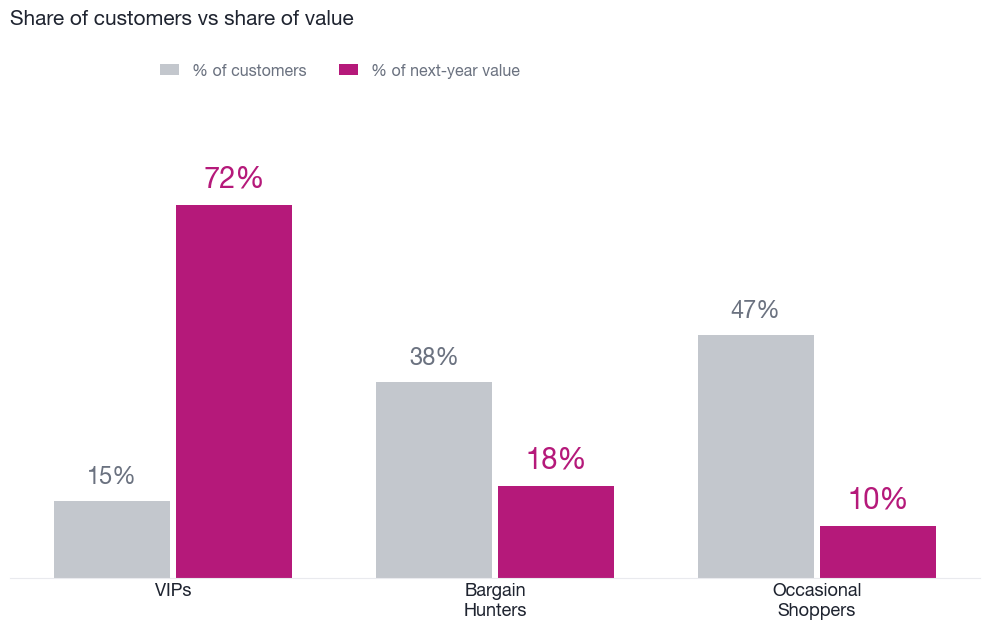

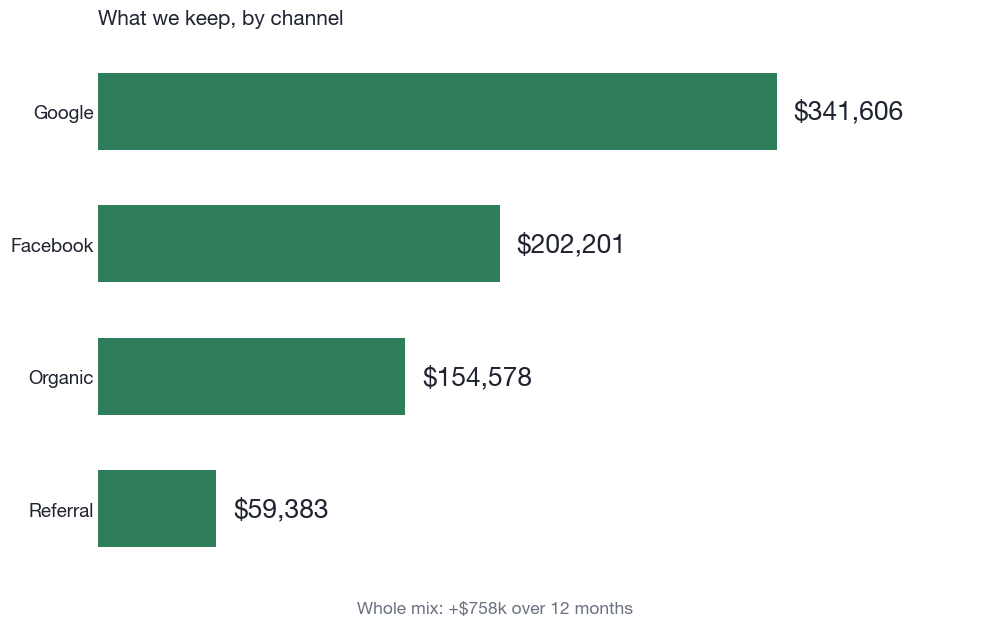

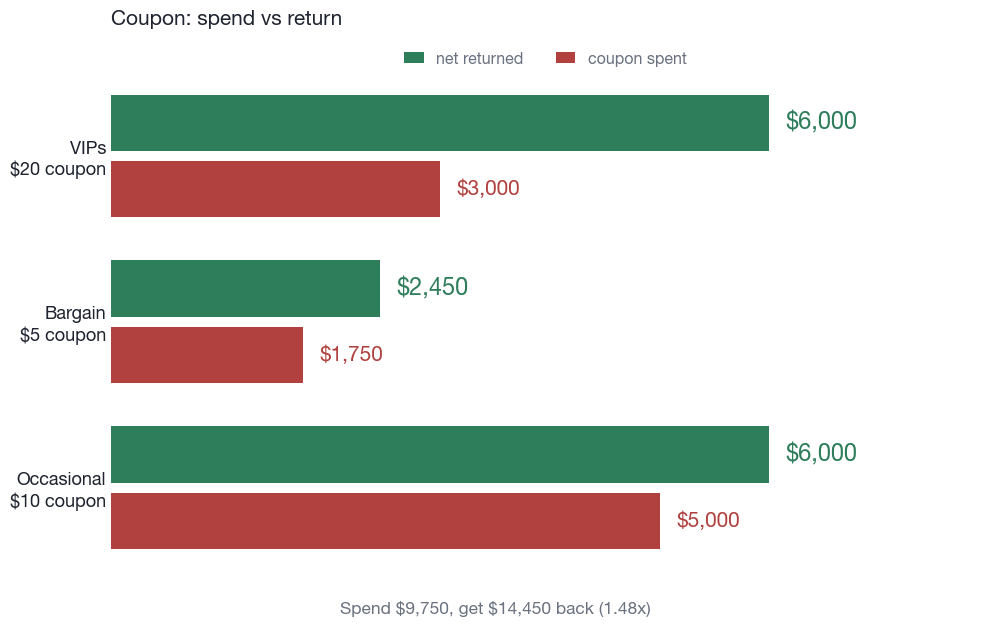

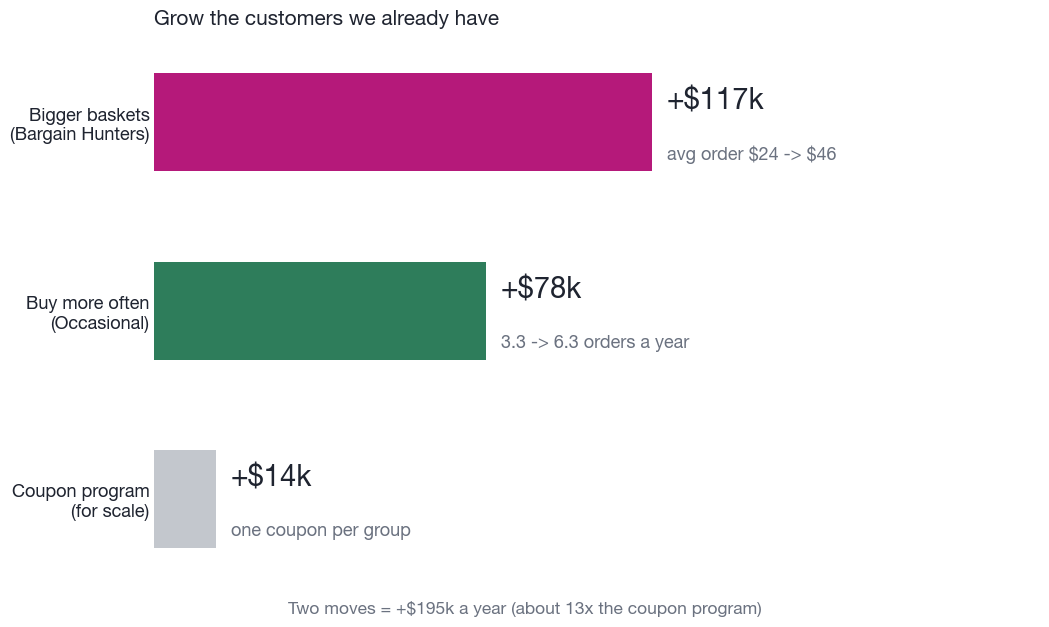

In [3]:
def _house(ax, hide="y"):
    plt.rcParams["font.family"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(False)
    ax.tick_params(length=0, colors=MUTED, labelsize=12)
    if hide == "y":
        ax.yaxis.set_visible(False)
        ax.spines["left"].set_visible(False)
        ax.spines["bottom"].set_color(GRID)
    else:
        ax.xaxis.set_visible(False)
        ax.spines["bottom"].set_visible(False)
        ax.spines["left"].set_visible(False)


def fig_concentration():
    fig, ax = plt.subplots(figsize=(10, 6.4))
    _house(ax, hide="y")

    n_total = len(seg)
    v_total = seg["future_value"].sum()
    cust_share = [(seg["segment"] == s).sum() / n_total * 100 for s in SEG_ORDER]
    val_share = [seg.loc[seg["segment"] == s, "future_value"].sum() / v_total * 100 for s in SEG_ORDER]

    x = np.arange(len(SEG_ORDER))
    w = 0.36
    ax.bar(x - w / 2 - 0.01, cust_share, width=w, color=GREY, label="% of customers")
    ax.bar(x + w / 2 + 0.01, val_share, width=w, color=MAGENTA, label="% of next-year value")

    top = max(max(cust_share), max(val_share))
    ax.set_ylim(0, top * 1.42)
    pad = top * 0.035

    for xi, v in zip(x - w / 2 - 0.01, cust_share):
        ax.text(xi, v + pad, f"{round(v)}%", ha="center", va="bottom",
                fontsize=17, color=MUTED)
    for xi, v in zip(x + w / 2 + 0.01, val_share):
        ax.text(xi, v + pad, f"{round(v)}%", ha="center", va="bottom",
                fontsize=21, fontweight="bold", color=MAGENTA)

    ax.set_xticks(x)
    ax.set_xticklabels(["VIPs", "Bargain\nHunters", "Occasional\nShoppers"],
                       fontsize=13, color=INK)
    ax.set_title("Share of customers vs share of value", loc="left",
                 fontsize=15, fontweight="bold", color=INK, pad=18)
    ax.legend(loc="upper center", bbox_to_anchor=(0.34, 1.0), ncol=2,
              frameon=False, fontsize=11.5, labelcolor=MUTED, handlelength=1.2)

    plt.tight_layout()
    plt.show()


def fig_acquisition():
    fig, ax = plt.subplots(figsize=(10, 6.4))
    _house(ax, hide="x")

    ch = chan.rename(columns={"channel_name": "acquisition_channel"})
    m = seg.merge(ch, on="acquisition_channel", how="left")
    g = m.groupby("acquisition_channel").agg(
        fv=("future_value", "sum"),
        n=("customer_id", "count"),
        rate=("revenue_share_rate", "first"),
        cps=("cost_per_signup", "first"),
    )
    g["kept"] = g["fv"] - g["fv"] * g["rate"] - g["n"] * g["cps"]
    g = g.sort_values("kept", ascending=False)

    y = np.arange(len(g))
    ax.barh(y, g["kept"].values, height=0.58, color=GREEN)
    ax.set_yticks(y)
    ax.set_yticklabels(g.index, fontsize=13.5, color=INK)
    ax.invert_yaxis()

    top = g["kept"].max()
    ax.set_xlim(0, top * 1.30)
    for yi, v in zip(y, g["kept"].values):
        ax.text(v + top * 0.025, yi, f"\${v:,.0f}", va="center", ha="left",
                fontsize=19, fontweight="bold", color=INK)

    ax.set_title("What we keep, by channel", loc="left",
                 fontsize=15, fontweight="bold", color=INK, pad=18)

    total = g["kept"].sum()
    fig.text(0.5, 0.04, f"Whole mix: +\${round(total / 1000):,.0f}k over 12 months",
             ha="center", va="center", fontsize=12.5, color=MUTED)

    plt.tight_layout(rect=[0, 0.075, 1, 1])
    plt.show()


def fig_coupon_spend_return():
    fig, ax = plt.subplots(figsize=(10, 6.4))
    _house(ax, hide="x")

    a = alloc.set_index("segment").loc[SEG_ORDER]
    short = {"VIPs": "VIPs", "Bargain Hunters": "Bargain", "Occasional Shoppers": "Occasional"}

    y = np.arange(len(a))
    off = 0.20
    ax.barh(y - off, a["net_revenue"].values, height=0.34, color=GREEN, label="net returned")
    ax.barh(y + off, a["cost"].values, height=0.34, color=RED, label="coupon spent")

    ax.set_yticks(y)
    ax.set_yticklabels([f"{short[s]}\n\${int(c)} coupon" for s, c in zip(a.index, a["coupon"])],
                       fontsize=13, color=INK)
    ax.invert_yaxis()

    top = max(a["net_revenue"].max(), a["cost"].max())
    ax.set_xlim(0, top * 1.32)
    for yi, v in zip(y - off, a["net_revenue"].values):
        ax.text(v + top * 0.025, yi, f"\${v:,.0f}", va="center", ha="left",
                fontsize=17, fontweight="bold", color=GREEN)
    for yi, v in zip(y + off, a["cost"].values):
        ax.text(v + top * 0.025, yi, f"\${v:,.0f}", va="center", ha="left",
                fontsize=15, color=RED)

    ax.set_title("Coupon: spend vs return", loc="left",
                 fontsize=15, fontweight="bold", color=INK, pad=34)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.07), ncol=2,
              frameon=False, fontsize=11.5, labelcolor=MUTED, handlelength=1.2)

    spend = a["cost"].sum()
    ret = a["net_revenue"].sum()
    fig.text(0.5, 0.04,
             f"Spend \${spend:,.0f}, get \${ret:,.0f} back ({ret / spend:.2f}x)",
             ha="center", va="center", fontsize=12.5, color=MUTED)

    plt.tight_layout(rect=[0, 0.075, 1, 1])
    plt.show()


def fig_migration():
    fig, ax = plt.subplots(figsize=(10.6, 6.4))
    _house(ax, hide="x")

    coupon_net = alloc["net_revenue"].sum()
    labels = ["Bigger baskets\n(Bargain Hunters)", "Buy more often\n(Occasional)", "Coupon program\n(for scale)"]
    values = [117000, 78000, coupon_net]
    colors = [MAGENTA, GREEN, GREY]
    subs = ["avg order \$24 -> \$46", "3.3 -> 6.3 orders a year", "one coupon per group"]

    y = np.arange(len(values))
    ax.barh(y, values, height=0.52, color=colors)
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=13, color=INK)
    ax.invert_yaxis()

    top = max(values)
    ax.set_xlim(0, top * 1.78)
    for yi, v in zip(y, values):
        ax.text(v + top * 0.03, yi - 0.11, f"+\${round(v / 1000):,.0f}k",
                va="center", ha="left", fontsize=21, fontweight="bold", color=INK)
    for yi, v, s in zip(y, values, subs):
        ax.text(v + top * 0.03, yi + 0.17, s,
                va="center", ha="left", fontsize=13, color=MUTED)

    ax.set_title("Grow the customers we already have", loc="left",
                 fontsize=15, fontweight="bold", color=INK, pad=18)

    two = values[0] + values[1]
    fig.text(0.5, 0.04,
             f"Two moves = +\${round(two / 1000):,.0f}k a year "
             f"(about {two / coupon_net:.0f}x the coupon program)",
             ha="center", va="center", fontsize=12.5, color=MUTED)

    plt.tight_layout(rect=[0, 0.075, 1, 1])
    plt.show()


fig_concentration()
fig_acquisition()
fig_coupon_spend_return()
fig_migration()


## Slide 2, Customer Segmentation ("Three Segments, Three Plays")

Claims: the three segment sizes, values, and behaviour (orders/year, average order, recency); and the
category "price tag" (premium aisles = 56% of revenue from 39% of purchases).

In [4]:
prof = seg.groupby("segment").agg(n=("customer_id","size"), value=("future_value","sum"),
        per_customer=("future_value","mean"), recency_days=("recency","mean"),
        orders_yr=("frequency","mean"), avg_order=("aov","mean"))
prof["pct_base"]   = (prof.n/len(seg)*100).round(0)
prof["value_share%"] = (prof.value/seg.future_value.sum()*100).round(1)
prof = prof.loc[["VIPs","Bargain Hunters","Occasional Shoppers"],
                ["n","pct_base","value","value_share%","per_customer","orders_yr","avg_order","recency_days"]]
print("Segment profile (matches the slide-2 cards):"); display(prof.round(1))

g = txseg.groupby("category").amount.agg(rev="sum", purch="count", avg_item="mean")
g["rev_share%"] = (g.rev/g.rev.sum()*100).round(0)
g["purch_share%"] = (g.purch/g.purch.sum()*100).round(0)
g["avg_item$"] = g.avg_item.round(0)
print("Category return (matches the 'Premium aisles' chart):")
display(g.loc[["Electronics","Home","Fashion","Beauty","Sports"], ["rev_share%","purch_share%","avg_item$"]])
prem = g.loc[["Electronics","Home"]]
check("Premium aisles (Electronics + Home)",
      f"{prem.rev.sum()/g.rev.sum()*100:.0f}% of revenue from {prem.purch.sum()/g.purch.sum()*100:.0f}% of purchases",
      "56% of revenue from 39% of purchases")

Segment profile (matches the slide-2 cards):


,n,pct_base,value,value_share%,per_customer,orders_yr,avg_order,recency_days
segment,,,,,,,,
VIPs,148,15.0,566227.9,72.4,3825.9,24.5,119.5,22.1
Bargain Hunters,380,38.0,138689.8,17.7,365.0,14.0,24.1,35.5
Occasional Shoppers,472,47.0,77676.6,9.9,164.6,3.3,54.8,153.1


Category return (matches the 'Premium aisles' chart):


,rev_share%,purch_share%,avg_item$
category,,,
Electronics,31.0,21.0,90.0
Home,25.0,19.0,82.0
Fashion,18.0,26.0,41.0
Beauty,15.0,23.0,41.0
Sports,11.0,11.0,59.0


- Premium aisles (Electronics + Home)
    deck : 56% of revenue from 39% of purchases
    data : 56% of revenue from 39% of purchases



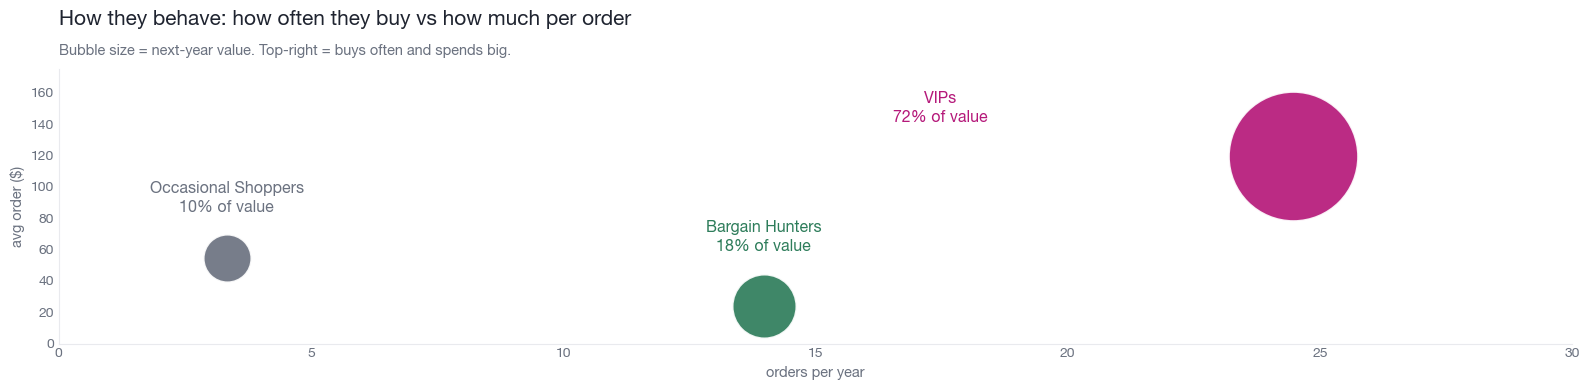

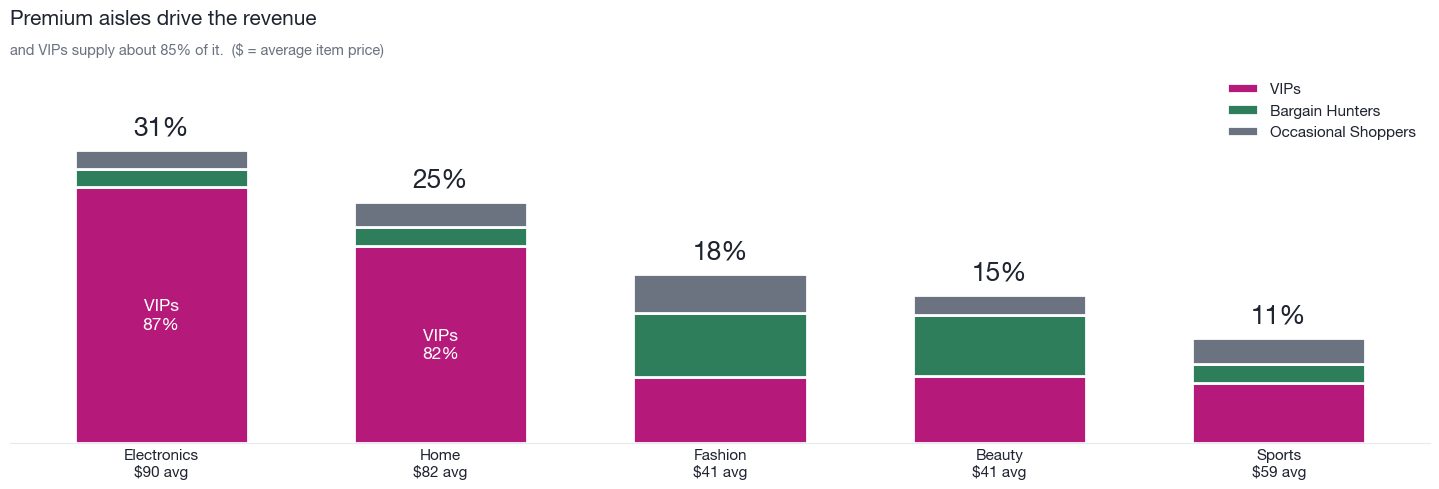

In [5]:
def fig_behaviour_map():
    plt.rcParams["font.family"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
    order = ["VIPs", "Bargain Hunters", "Occasional Shoppers"]
    g = (seg.groupby("segment")
            .agg(freq=("frequency", "mean"), aov=("aov", "mean"), value=("future_value", "sum"))
            .reindex(order))
    g["share"] = g["value"] / g["value"].sum()

    fig, ax = plt.subplots(figsize=(16, 4))
    label_pos = {"VIPs": (-7.0, 20), "Bargain Hunters": (0, 33), "Occasional Shoppers": (0, 27)}
    for name, r in g.iterrows():
        ax.scatter(r["freq"], r["aov"], s=r["share"] * 12000, color=SEGC[name],
                   alpha=0.92, edgecolors="white", linewidths=1.5, zorder=3)
        dx, dy = label_pos[name]
        ax.text(r["freq"] + dx, r["aov"] + dy,
                "{}\n{:.0f}% of value".format(name, r["share"] * 100),
                ha="center", va="bottom", fontsize=11.5, fontweight="bold",
                color=SEGC[name], linespacing=1.35, zorder=4)

    ax.set_xlim(0, 30)
    ax.set_ylim(0, 175)
    ax.set_xlabel("orders per year", fontsize=10.5, color=MUTED)
    ax.set_ylabel("avg order (\$)", fontsize=10.5, color=MUTED)
    ax.set_title("How they behave: how often they buy vs how much per order",
                 loc="left", fontsize=15, fontweight="bold", color=INK, pad=32)
    ax.annotate("Bubble size = next-year value. Top-right = buys often and spends big.",
                xy=(0, 1), xycoords="axes fraction", xytext=(0, 8),
                textcoords="offset points", ha="left", va="bottom",
                fontsize=10.5, color=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("bottom", "left"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(length=0, colors=MUTED, labelsize=10)
    plt.tight_layout()
    plt.show()


def fig_category_return():
    plt.rcParams["font.family"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]
    order = ["VIPs", "Bargain Hunters", "Occasional Shoppers"]
    total = txseg["amount"].sum()
    cat_rev = txseg.groupby("category")["amount"].sum().sort_values(ascending=False)
    cats = list(cat_rev.index)
    height = cat_rev / total * 100.0
    avg = txseg.groupby("category")["amount"].mean()
    piv = (txseg.pivot_table(index="category", columns="segment", values="amount", aggfunc="sum")
                .reindex(index=cats, columns=order).fillna(0.0))
    share = piv.div(piv.sum(axis=1), axis=0)

    fig, ax = plt.subplots(figsize=(14.5, 5))
    x = np.arange(len(cats))
    bottom = np.zeros(len(cats))
    for name in order:
        vals = (share[name] * height).values
        ax.bar(x, vals, bottom=bottom, width=0.62, color=SEGC[name], label=name,
               edgecolor="white", linewidth=2, zorder=3)
        bottom = bottom + vals

    for i, c in enumerate(cats):
        ax.text(x[i], height[c] + 1.1, "{:.0f}%".format(height[c]), ha="center", va="bottom",
                fontsize=19, fontweight="bold", color=INK)
        if c in ("Electronics", "Home") and share.loc[c, "VIPs"] > 0.25:
            seg_h = share.loc[c, "VIPs"] * height[c]
            ax.text(x[i], seg_h / 2.0, "VIPs\n{:.0f}%".format(share.loc[c, "VIPs"] * 100),
                    ha="center", va="center", fontsize=12.5, fontweight="bold",
                    color="white", linespacing=1.3, zorder=4)

    ax.set_xticks(x)
    ax.set_xticklabels(["{}\n\${:.0f} avg".format(c, avg[c]) for c in cats],
                       fontsize=11, color=INK)
    ax.set_ylim(0, height.max() * 1.28)
    ax.set_title("Premium aisles drive the revenue",
                 loc="left", fontsize=15, fontweight="bold", color=INK, pad=32)
    ax.annotate("and VIPs supply about 85% of it.  (\$ = average item price)",
                xy=(0, 1), xycoords="axes fraction", xytext=(0, 8),
                textcoords="offset points", ha="left", va="bottom",
                fontsize=10.5, color=MUTED)
    ax.get_yaxis().set_visible(False)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(length=0, colors=INK, labelsize=11)
    ax.legend(frameon=False, loc="upper right", fontsize=11, labelcolor=INK)
    plt.tight_layout()
    plt.show()


fig_behaviour_map()
fig_category_return()


## Slide 3, CLV Insights ("Behaviour Predicts Spend, Almost to the Dollar")

Claims: past spend dominates the drivers (~\$1,304, ~7x the next); demographics add ~\$0; the model
(Gradient Boosting) predicts within ~\$15; and the whole model reduces to three yes/no questions.

In [6]:
print("Drivers, dollars of extra forecast error if we scramble each signal (permutation importance):")
display(fi.rename(columns={"rmse_added_if_shuffled":"$ error added"}).round(0))
check("Past spend vs next driver", f"${fi.iloc[0,0]:.0f} vs ${fi.iloc[1,0]:.0f} ({fi.iloc[0,0]/fi.iloc[1,0]:.0f}x)", "$1,304, about 7x the next")
check("Held-out accuracy", f"typical miss ${metrics['test_mae']:.0f} (MAE), ${metrics['test_rmse']:.0f} (RMSE), R2 {metrics['test_r2']}",
      "within about $15; R2 ~1.0 (used in notebook, not on slide)")

# The 'three questions' surrogate tree (a shallow stand-in for the Gradient Boosting model)
t = DecisionTreeRegressor(max_depth=2, random_state=42).fit(seg[["monetary","frequency","aov","age"]], seg.future_value)
print("Surrogate tree, the 'three questions' on slide 3:")
print(export_text(t, feature_names=["monetary","frequency","aov","age"], decimals=0))
print("R2 of the 3-question tree vs actual value:",
      round(1-((seg.future_value-t.predict(seg[['monetary','frequency','aov','age']]))**2).sum()
             /((seg.future_value-seg.future_value.mean())**2).sum(), 3))

Drivers, dollars of extra forecast error if we scramble each signal (permutation importance):


,$ error added
monetary,1304.0
aov,190.0
frequency,85.0
pct_electronics,24.0
age,13.0
pct_fashion,1.0
recency,0.0
pct_sports,0.0
pct_beauty,0.0
country,0.0


- Past spend vs next driver
    deck : $1,304, about 7x the next
    data : $1304 vs $190 (7x)

- Held-out accuracy
    deck : within about $15; R2 ~1.0 (used in notebook, not on slide)
    data : typical miss $15 (MAE), $24 (RMSE), R2 0.9996

Surrogate tree, the 'three questions' on slide 3:
|--- aov <= 96
|   |--- frequency <= 6
|   |   |--- value: [158]
|   |--- frequency >  6
|   |   |--- value: [363]
|--- aov >  96
|   |--- monetary <= 2972
|   |   |--- value: [3416]
|   |--- monetary >  2972
|   |   |--- value: [4350]

R2 of the 3-question tree vs actual value: 0.986


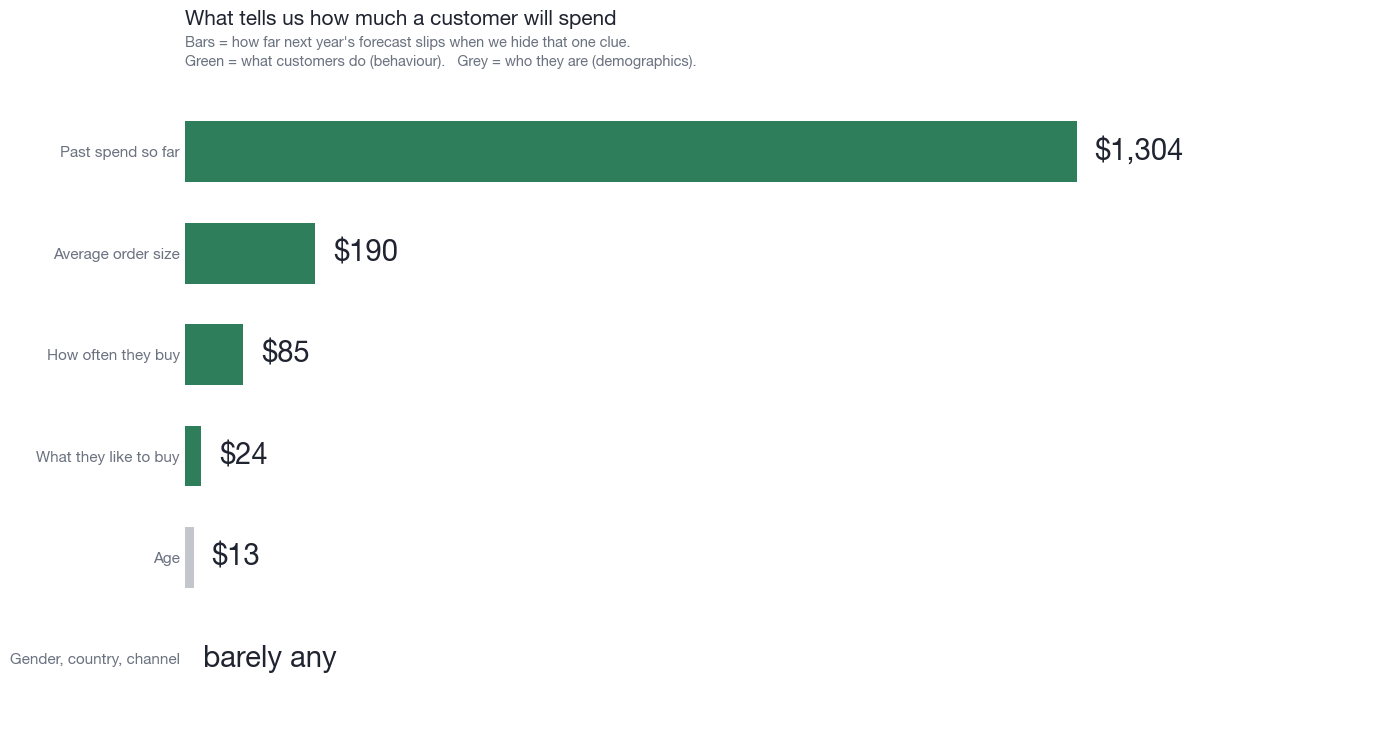

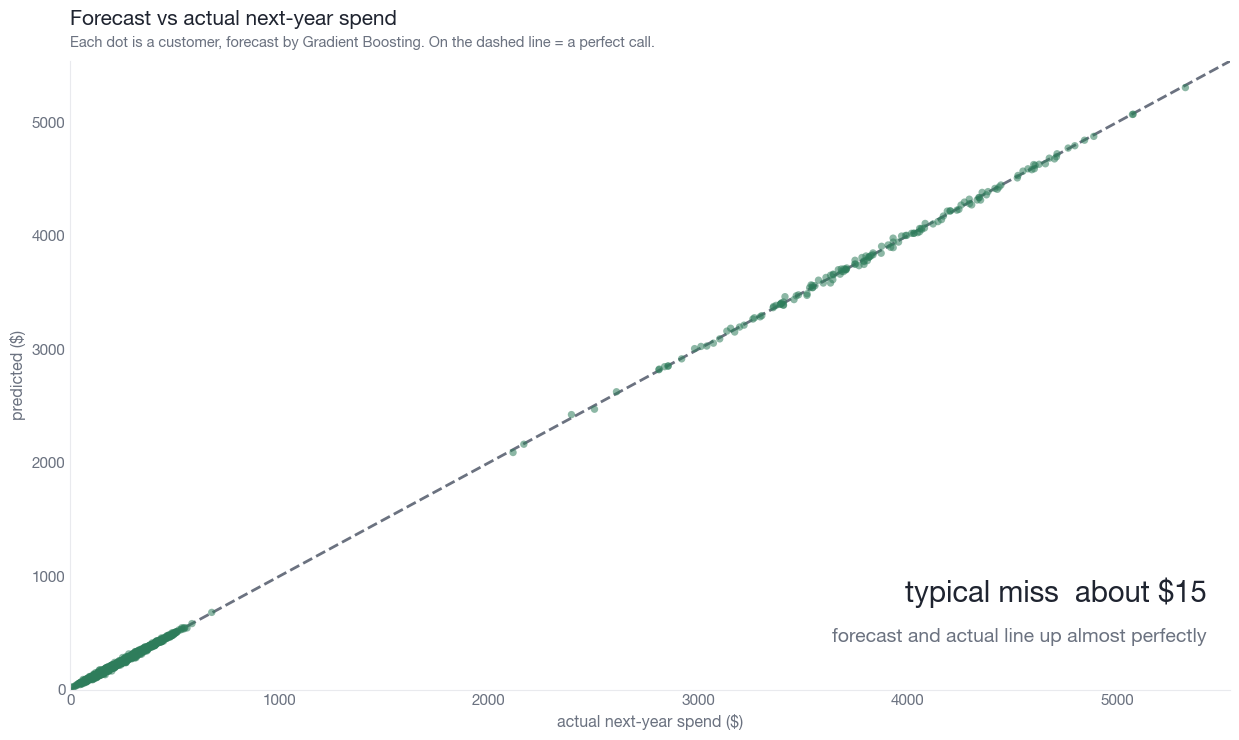

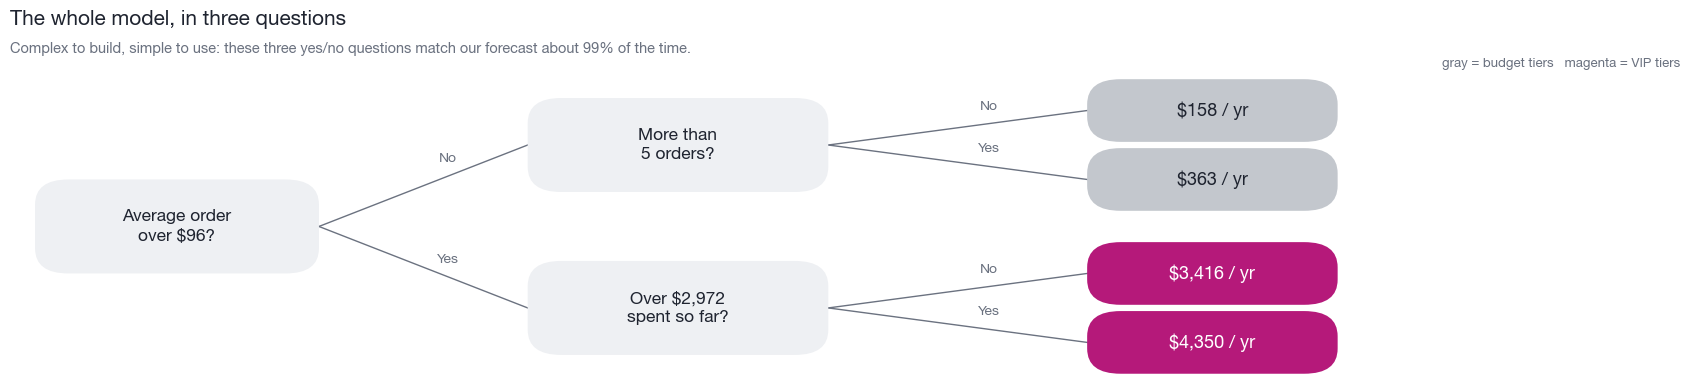

In [7]:
plt.rcParams["font.family"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]


def _clean(ax, keep=()):
    for s in ("top", "right", "bottom", "left"):
        ax.spines[s].set_visible(s in keep)
        if s in keep:
            ax.spines[s].set_color(GRID)
    ax.tick_params(length=0, colors=MUTED, labelsize=11)


def _subtitle(ax, lines):
    offs = [22, 8] if len(lines) == 2 else [8]
    for txt, dy in zip(lines, offs):
        ax.annotate(txt, xy=(0, 1), xycoords="axes fraction",
                    xytext=(0, dy), textcoords="offset points",
                    ha="left", va="bottom", fontsize=10.5, color=MUTED)


def _fi(name):
    row = fi.loc[name]
    return float(row.iloc[0]) if hasattr(row, "iloc") else float(row)


def _metric(name):
    if hasattr(metrics, "columns"):
        v = metrics.loc[name]
        return float(v.iloc[0]) if hasattr(v, "iloc") else float(v)
    return float(metrics[name])


def fig_clv_drivers():
    rows = [
        ("Past spend so far",        _fi("monetary"),        GREEN),
        ("Average order size",       _fi("aov"),             GREEN),
        ("How often they buy",       _fi("frequency"),       GREEN),
        ("What they like to buy",    _fi("pct_electronics"), GREEN),
        ("Age",                      _fi("age"),             GREY),
        ("Gender, country, channel", 0.0,                    GREY),
    ]
    labels = [r[0] for r in rows]
    vals   = [r[1] for r in rows]
    cols   = [r[2] for r in rows]
    top    = max(vals)

    fig, ax = plt.subplots(figsize=(14, 7.5))
    ypos = np.arange(len(rows))
    ax.barh(ypos, vals, height=0.6, color=cols)

    for i, v in enumerate(vals):
        txt = "barely any" if i == len(rows) - 1 else "\${:,.0f}".format(v)
        ax.text(v + top * 0.02, i, txt, va="center", ha="left",
                fontsize=21, fontweight="bold", color=INK)

    ax.set_yticks(ypos)
    ax.set_yticklabels(labels, fontsize=14, color=INK)
    ax.set_xlim(0, top * 1.34)
    ax.set_ylim(-0.7, len(rows) - 0.3)
    ax.invert_yaxis()
    ax.get_xaxis().set_visible(False)
    _clean(ax)
    ax.set_title("What tells us how much a customer will spend", loc="left",
                 fontsize=15, fontweight="bold", color=INK, pad=40)
    _subtitle(ax, ["Bars = how far next year's forecast slips when we hide that one clue.",
                   "Green = what customers do (behaviour).   Grey = who they are (demographics)."])
    plt.tight_layout()
    plt.show()


def fig_clv_predict():
    x = preds["actual_clv"].values
    y = preds["predicted_clv"].values
    hi = float(max(x.max(), y.max())) * 1.04

    fig, ax = plt.subplots(figsize=(12.5, 7.5))
    ax.plot([0, hi], [0, hi], linestyle="--", linewidth=2, color=MUTED, zorder=1)
    ax.scatter(x, y, s=28, alpha=0.55, color=GREEN, edgecolor="none", zorder=2)

    ax.set_xlim(0, hi)
    ax.set_ylim(0, hi)
    ax.set_xlabel("actual next-year spend (\$)", fontsize=11.5, color=MUTED)
    ax.set_ylabel("predicted (\$)", fontsize=11.5, color=MUTED)
    _clean(ax, keep=("bottom", "left"))

    mae = round(_metric("test_mae"))
    ax.text(0.98, 0.13, "typical miss  about \${:,.0f}".format(mae),
            transform=ax.transAxes, ha="right", va="bottom",
            fontsize=21, fontweight="bold", color=INK)
    ax.text(0.98, 0.07, "forecast and actual line up almost perfectly",
            transform=ax.transAxes, ha="right", va="bottom",
            fontsize=14, color=MUTED)

    ax.set_title("Forecast vs actual next-year spend", loc="left",
                 fontsize=15, fontweight="bold", color=INK, pad=26)
    _subtitle(ax, ["Each dot is a customer, forecast by Gradient Boosting. "
                   "On the dashed line = a perfect call."])
    plt.tight_layout()
    plt.show()


def fig_clv_tree():
    from matplotlib.patches import FancyBboxPatch
    from sklearn.tree import DecisionTreeRegressor

    feats = ["aov", "frequency", "monetary"]
    t = DecisionTreeRegressor(max_depth=2, random_state=42).fit(seg[feats], seg["future_value"])
    tr = t.tree_
    L, R = tr.children_left, tr.children_right

    def question(node):
        f = feats[tr.feature[node]]
        thr = tr.threshold[node]
        if f == "aov":
            return "Average order\nover \${:,.0f}?".format(thr)
        if f == "frequency":
            return "More than\n{:,.0f} orders?".format(np.floor(thr))
        return "Over \${:,.0f}\nspent so far?".format(thr)

    def leaf(node):
        return "\${:,.0f} / yr".format(tr.value[node].ravel()[0])

    fig, ax = plt.subplots(figsize=(17, 4))
    ax.axis("off")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    def box(x, y, w, h, text, fill, tcol, fs, edge=None):
        ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h,
                                    boxstyle="round,pad=0.02,rounding_size=0.02",
                                    linewidth=0 if edge is None else 1,
                                    facecolor=fill, edgecolor=fill if edge is None else edge,
                                    transform=ax.transAxes, zorder=3, mutation_aspect=4.0))
        ax.text(x, y, text, ha="center", va="center", fontsize=fs,
                fontweight="bold", color=tcol, zorder=4, linespacing=1.35)

    def link(x0, y0, x1, y1, label):
        ax.plot([x0, x1], [y0, y1], color=MUTED, linewidth=1, zorder=1)
        f = 0.62
        ax.text(x0 + f * (x1 - x0), y0 + f * (y1 - y0) + 0.035, label,
                ha="center", va="bottom", fontsize=10, fontweight="bold",
                color=MUTED, zorder=2)

    xr, xm, xl = 0.10, 0.40, 0.72
    wr, wm, wl = 0.13, 0.14, 0.11
    hr, hm, hl = 0.14, 0.14, 0.04
    y_leaf = [0.86, 0.64, 0.34, 0.12]
    y_no, y_yes = 0.75, 0.23
    y_root = 0.49

    box(xr, y_root, wr, hr, question(0), PANEL, INK, 12.5)
    box(xm, y_no, wm, hm, question(L[0]), PANEL, INK, 12.5)
    box(xm, y_yes, wm, hm, question(R[0]), PANEL, INK, 12.5)

    box(xl, y_leaf[0], wl, hl, leaf(L[L[0]]), GREY, INK, 13)
    box(xl, y_leaf[1], wl, hl, leaf(R[L[0]]), GREY, INK, 13)
    box(xl, y_leaf[2], wl, hl, leaf(L[R[0]]), MAGENTA, "white", 13)
    box(xl, y_leaf[3], wl, hl, leaf(R[R[0]]), MAGENTA, "white", 13)

    rx, mxl, mxr, lx = xr + wr / 2 + 0.02, xm - wm / 2 - 0.02, xm + wm / 2 + 0.02, xl - wl / 2 - 0.02
    link(rx, y_root, mxl, y_no, "No")
    link(rx, y_root, mxl, y_yes, "Yes")
    link(mxr, y_no, lx, y_leaf[0], "No")
    link(mxr, y_no, lx, y_leaf[1], "Yes")
    link(mxr, y_yes, lx, y_leaf[2], "No")
    link(mxr, y_yes, lx, y_leaf[3], "Yes")

    ax.text(1.0, 0.99, "gray = budget tiers   magenta = VIP tiers", ha="right", va="bottom",
            fontsize=9.5, color=MUTED, transform=ax.transAxes)
    ax.set_title("The whole model, in three questions", loc="left",
                 fontsize=15, fontweight="bold", color=INK, pad=30)
    _subtitle(ax, ["Complex to build, simple to use: these three yes/no questions "
                   "match our forecast about 99% of the time."])
    plt.tight_layout()
    plt.show()


fig_clv_drivers()
fig_clv_predict()
fig_clv_tree()


## Slide 4, Coupon Strategy ("Set the Budget, Then Aim It")

Claims: the optimized coupon plan (VIPs \$20, Bargain \$5, Occasional \$10) returns +\$14,450 net on
\$9,750 (1.48x, \$250 unspent). The "where to spend" rule: coupon only where a discount can win a NEW
sale, not where people buy anyway. VIPs own Electronics/Home (82 to 87%), so a VIP discount is a
giveaway (make it a loyalty perk). Refined by repeat-buying: Occasional Shoppers are the clean coupon
(one-off Fashion/Beauty buyers); Bargain Hunters buy those aisles habitually (about 5x, 96% repeat),
so they are a test or a bundle, not a flat discount.

*The per-coupon net revenue comes from the lift curves in solutions.ipynb (a model assumption); the
totals below are read from `coupon_allocation.csv`.*

In [8]:
print("Coupon allocation (from outputs/coupon_allocation.csv):"); display(alloc)
check("Coupon plan totals",
      f"spend ${alloc.cost.sum():,.0f}, net ${alloc.net_revenue.sum():,.0f}, {alloc.net_revenue.sum()/alloc.cost.sum():.2f}x, ${10000-alloc.cost.sum():,.0f} unspent",
      "$9,750 -> +$14,450, 1.48x, $250 unspent")
print("Net per $1 by segment:", {r.segment: round(r.net_revenue/r.cost,2) for r in alloc.itertuples()})

piv = txseg.pivot_table(index="segment", columns="category", values="amount", aggfunc="sum")
print("\nAisle revenue by segment, $ (matches the 'where each coupon goes' matrix):")
display(piv.loc[["VIPs","Bargain Hunters","Occasional Shoppers"], ["Fashion","Beauty","Sports","Home","Electronics"]].round(0).astype(int))
for c in ["Electronics","Home"]:
    v = txseg[(txseg.segment=="VIPs")&(txseg.category==c)].amount.sum()
    check(f"VIP share of {c} revenue", f"{v/txseg[txseg.category==c].amount.sum()*100:.0f}%", "82 to 87% is VIPs who buy anyway")
pen = {c: f"{txseg[(txseg.segment=='VIPs')&(txseg.category==c)].customer_id.nunique()/seg[seg.segment=='VIPs'].shape[0]*100:.0f}%" for c in ['Fashion','Beauty','Sports','Home','Electronics']}
check("VIP average item price & aisle penetration", f"${txseg[txseg.segment=='VIPs'].amount.mean():.0f}/item; penetration {pen}",
      "~$119/item, buys every aisle (so a coupon is a giveaway; make it a loyalty perk)")

# Refined 'where to spend': would the coupon win a NEW sale, or subsidise a habit?
# Repeat-buying by segment x aisle (high repeat = they buy anyway = deadweight risk).
print("\nRepeat-buying in Fashion/Beauty (backs the coupon-vs-test call on the matrix):")
for s in ["Bargain Hunters", "Occasional Shoppers"]:
    for c in ["Fashion", "Beauty"]:
        cc = txseg[(txseg.segment == s) & (txseg.category == c)]
        b = cc.customer_id.nunique(); rep = (cc.groupby("customer_id").size() >= 2).mean() * 100
        verdict = "clean coupon (one-off buyers, a discount can win a new sale)" if s == "Occasional Shoppers" \
                  else "habitual, so test or bundle, not a flat discount"
        check(f"{s} x {c}", f"{len(cc)/b:.1f} buys/buyer, {rep:.0f}% repeat buyers", verdict)


Coupon allocation (from outputs/coupon_allocation.csv):


,segment,population,coupon,cost,net_revenue
0,VIPs,150,20,3000,6000
1,Bargain Hunters,350,5,1750,2450
2,Occasional Shoppers,500,10,5000,6000


- Coupon plan totals
    deck : $9,750 -> +$14,450, 1.48x, $250 unspent
    data : spend $9,750, net $14,450, 1.48x, $250 unspent

Net per $1 by segment: {'VIPs': 2.0, 'Bargain Hunters': 1.4, 'Occasional Shoppers': 1.2}

Aisle revenue by segment, $ (matches the 'where each coupon goes' matrix):


category,Fashion,Beauty,Sports,Home,Electronics
segment,,,,,
VIPs,43897,44744,40414,132048,171799
Bargain Hunters,43097,40871,12640,12768,11826
Occasional Shoppers,26221,13427,17099,16662,12804


- VIP share of Electronics revenue
    deck : 82 to 87% is VIPs who buy anyway
    data : 87%

- VIP share of Home revenue
    deck : 82 to 87% is VIPs who buy anyway
    data : 82%

- VIP average item price & aisle penetration
    deck : ~$119/item, buys every aisle (so a coupon is a giveaway; make it a loyalty perk)
    data : $120/item; penetration {'Fashion': '91%', 'Beauty': '95%', 'Sports': '86%', 'Home': '100%', 'Electronics': '100%'}


Repeat-buying in Fashion/Beauty (backs the coupon-vs-test call on the matrix):
- Bargain Hunters x Fashion
    deck : habitual, so test or bundle, not a flat discount
    data : 5.1 buys/buyer, 96% repeat buyers

- Bargain Hunters x Beauty
    deck : habitual, so test or bundle, not a flat discount
    data : 5.0 buys/buyer, 96% repeat buyers

- Occasional Shoppers x Fashion
    deck : clean coupon (one-off buyers, a discount can win a new sale)
    data : 1.5 buys/buyer, 43% repeat buyers

- Occasional Shoppers x Beauty
    deck : clean coupon (

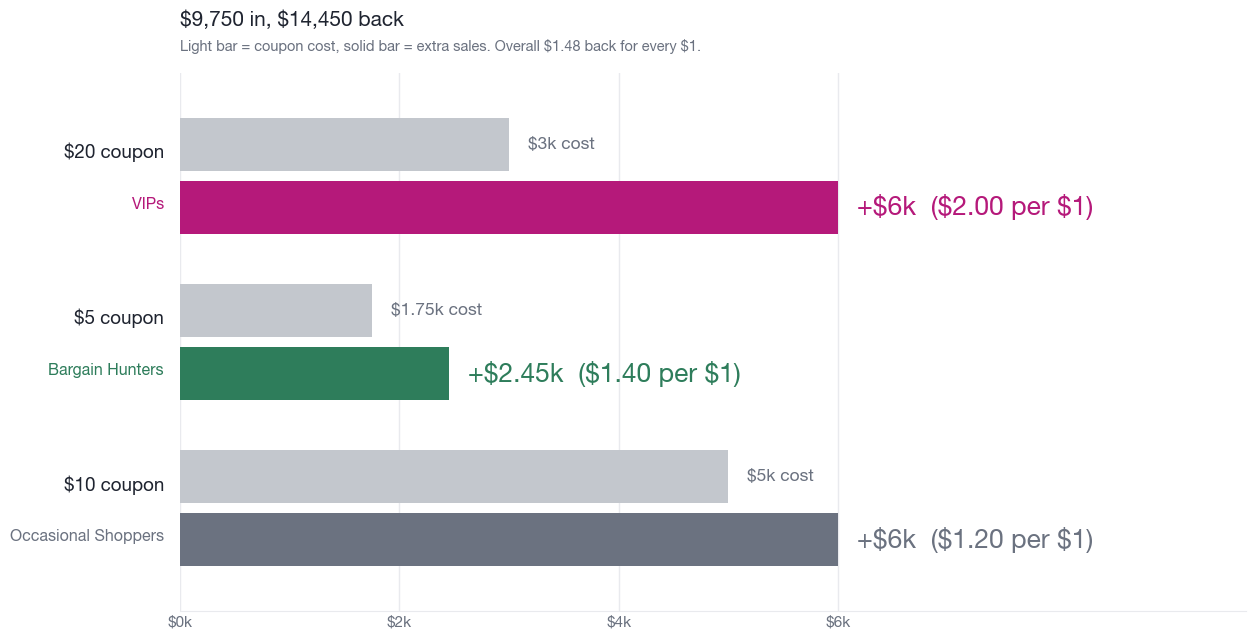

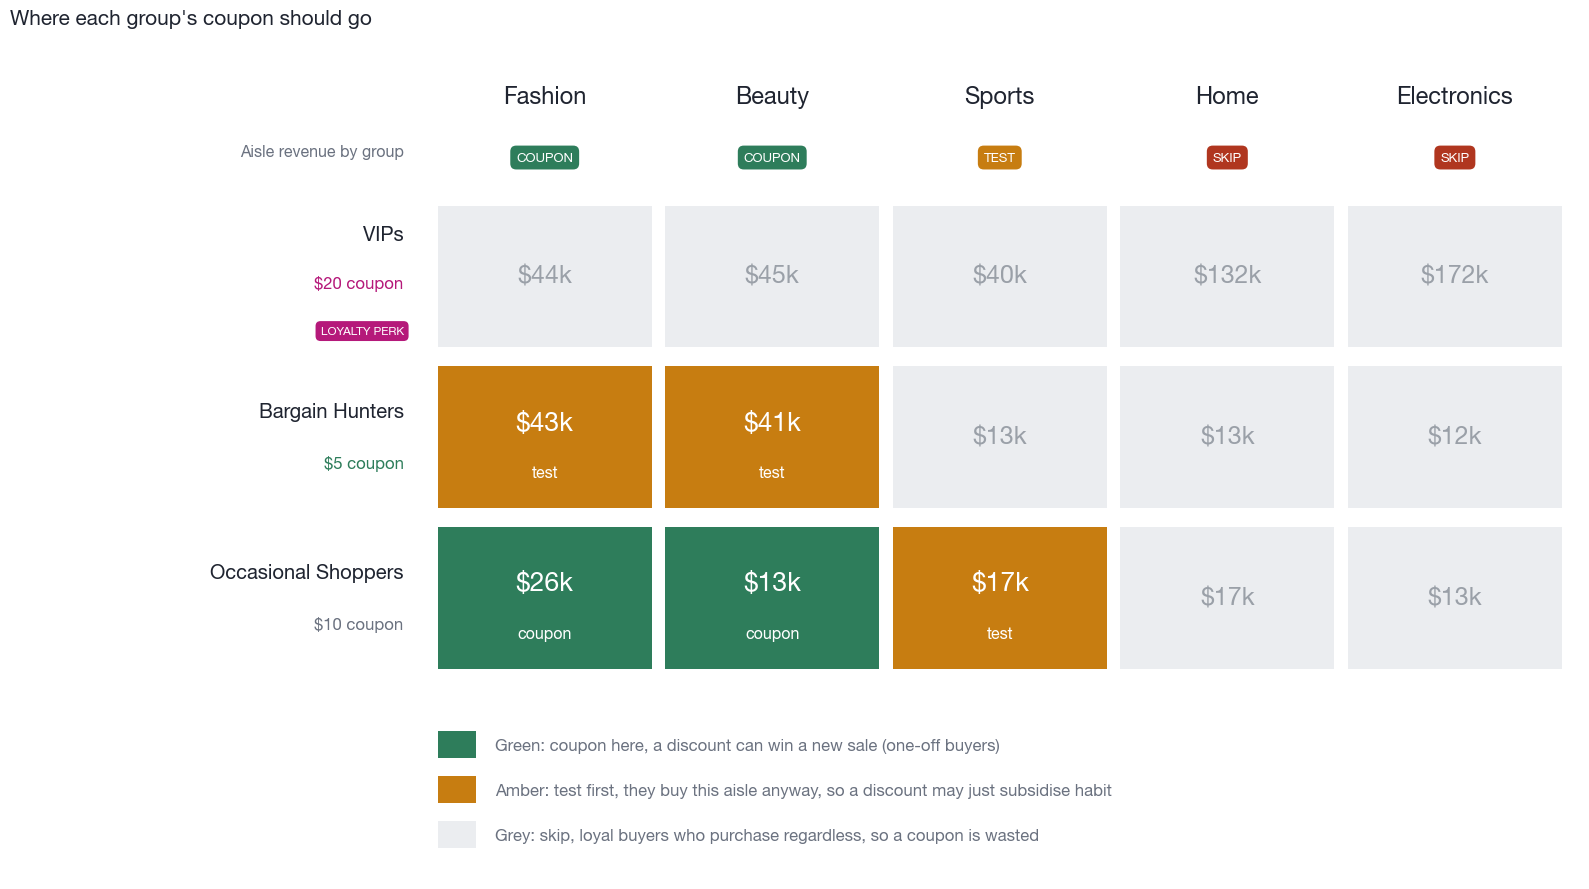

In [9]:
def fig_coupon_roi():
    order = ["VIPs", "Bargain Hunters", "Occasional Shoppers"]
    a = alloc.set_index("segment").loc[order]
    tot_cost, tot_net = a["cost"].sum(), a["net_revenue"].sum()

    def k(v):
        return "\\$%gk" % round(v / 1000.0, 2)

    fig, ax = plt.subplots(figsize=(15, 6.5))
    h = 0.32
    for i, s in enumerate(order):
        cost, net = a.loc[s, "cost"], a.loc[s, "net_revenue"]
        ratio = net / cost
        ax.barh(i - 0.19, cost, height=h, color=GREY, zorder=3)
        ax.barh(i + 0.19, net, height=h, color=SEGC[s], zorder=3)
        ax.text(cost + tot_net * 0.012, i - 0.19, k(cost) + " cost", va="center",
                ha="left", fontsize=12.5, color=MUTED, zorder=4)
        ax.text(net + tot_net * 0.012, i + 0.19,
                "+%s  (\\$%.2f per \\$1)" % (k(net), ratio), va="center", ha="left",
                fontsize=19, fontweight="bold", color=SEGC[s], zorder=4)
        ax.text(-0.015, i - 0.14, "\\$%d coupon" % a.loc[s, "coupon"],
                transform=ax.get_yaxis_transform(), ha="right", va="center",
                fontsize=13.5, fontweight="bold", color=INK)
        ax.text(-0.015, i + 0.17, s, transform=ax.get_yaxis_transform(),
                ha="right", va="center", fontsize=11.5, fontweight="bold", color=SEGC[s])

    top = max(a["net_revenue"].max(), a["cost"].max())
    ax.set_xlim(0, top * 1.62)
    ax.set_ylim(-0.62, len(order) - 0.38)
    ax.invert_yaxis()
    ax.set_yticks([])
    step = 2000
    ticks = np.arange(0, top + step, step)
    ax.set_xticks(ticks)
    ax.set_xticklabels(["\\$%dk" % (t / 1000) for t in ticks], fontsize=11, color=MUTED)
    ax.xaxis.grid(True, color=GRID, linewidth=1, zorder=0)
    ax.set_axisbelow(True)
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(length=0, colors=MUTED)

    ax.set_title("\\$%s in, \\$%s back" % (format(tot_cost, ",.0f"), format(tot_net, ",.0f")),
                 loc="left", fontsize=15, fontweight="bold", color=INK, pad=34)
    ax.text(0, 1.035, "Light bar = coupon cost, solid bar = extra sales. "
            "Overall \\$%.2f back for every \\$1." % (tot_net / tot_cost),
            transform=ax.transAxes, ha="left", va="bottom", fontsize=10.5, color=MUTED)
    plt.tight_layout(rect=(0.155, 0, 1, 1))
    plt.show()


def fig_coupon_where():
    rows = ["VIPs", "Bargain Hunters", "Occasional Shoppers"]
    cols = ["Fashion", "Beauty", "Sports", "Home", "Electronics"]
    rev = (txseg.pivot_table(index="segment", columns="category", values="amount",
                             aggfunc="sum", fill_value=0)
           .reindex(index=rows, columns=cols, fill_value=0))
    coup = alloc.set_index("segment")["coupon"]
    SKIP = "#ebedf0"

    def rule(s, c):
        if s == "Occasional Shoppers" and c in ("Fashion", "Beauty"):
            return "coupon"
        if (s == "Bargain Hunters" and c in ("Fashion", "Beauty")) or \
           (s == "Occasional Shoppers" and c == "Sports"):
            return "test"
        return "skip"

    fill = {"coupon": GREEN, "test": AMBER, "skip": SKIP}

    fig, ax = plt.subplots(figsize=(16, 9))
    for i, s in enumerate(rows):
        yc = -(i + 0.5)
        for j, c in enumerate(cols):
            r = rule(s, c)
            ax.add_patch(plt.Rectangle((j + 0.03, -(i + 1) + 0.06), 0.94, 0.88,
                                       facecolor=fill[r], edgecolor="none"))
            val = "\\$%.0fk" % (rev.loc[s, c] / 1000.0)
            if r == "skip":
                ax.text(j + 0.5, yc, val, ha="center", va="center", fontsize=18,
                        fontweight="bold", color="#9aa0a8")
            else:
                ax.text(j + 0.5, yc + 0.09, val, ha="center", va="center", fontsize=19,
                        fontweight="bold", color="white")
                ax.text(j + 0.5, yc - 0.22, r, ha="center", va="center", fontsize=11.5,
                        style="italic", color="white")
        ax.text(-0.12, yc + (0.26 if s == "VIPs" else 0.16), s, ha="right", va="center",
                fontsize=14.5, fontweight="bold", color=INK)
        ax.text(-0.12, yc - (0.04 if s == "VIPs" else 0.16), "\\$%d coupon" % coup[s],
                ha="right", va="center", fontsize=12, fontweight="bold", color=SEGC[s])
        if s == "VIPs":
            ax.text(-0.12, yc - 0.34, "LOYALTY PERK", ha="right", va="center", fontsize=8.5,
                    fontweight="bold", color="white",
                    bbox=dict(boxstyle="round,pad=0.42", facecolor=MAGENTA, edgecolor="none"))

    badge = {"Fashion": ("COUPON", GREEN), "Beauty": ("COUPON", GREEN),
             "Sports": ("TEST", AMBER), "Home": ("SKIP", "#b0361f"),
             "Electronics": ("SKIP", "#b0361f")}
    for j, c in enumerate(cols):
        ax.text(j + 0.5, 0.62, c, ha="center", va="center", fontsize=17,
                fontweight="bold", color=INK)
        lab, col = badge[c]
        ax.text(j + 0.5, 0.24, lab, ha="center", va="center", fontsize=9.5,
                fontweight="bold", color="white",
                bbox=dict(boxstyle="round,pad=0.45", facecolor=col, edgecolor="none"))
    ax.text(-0.12, 0.28, "Aisle revenue by group", ha="right", va="center",
            fontsize=11.5, style="italic", color=MUTED)

    legend = [(GREEN, "Green: coupon here, a discount can win a new sale (one-off buyers)"),
              (AMBER, "Amber: test first, they buy this aisle anyway, so a discount may just subsidise habit"),
              (SKIP, "Grey: skip, loyal buyers who purchase regardless, so a coupon is wasted")]
    for n, (col, txt) in enumerate(legend):
        y = -3.42 - n * 0.28
        ax.add_patch(plt.Rectangle((0.03, y - 0.08), 0.17, 0.17, facecolor=col, edgecolor="none"))
        ax.text(0.28, y, txt, ha="left", va="center", fontsize=12, color=MUTED)

    ax.set_xlim(-1.85, 5.05)
    ax.set_ylim(-4.25, 0.95)
    ax.axis("off")
    ax.set_title("Where each group's coupon should go", loc="left", fontsize=15,
                 fontweight="bold", color=INK, pad=14)
    plt.tight_layout()
    plt.show()


fig_coupon_roi()
fig_coupon_where()


## Slide 5, Data-Driven Roadmap ("Prove the Small Bet, Then Scale the Biggest Lever")

Claims: the lapsed pool (~100, ~1.6% of value, no VIPs, over-index Sports/Home); and the
"prize, to scale" bar (coupon \$14,450 vs grow the base \$195k vs restart acquisition \$758k).

In [10]:
lap = seg[seg.recency > 240]   # lapsed = no purchase in ~8+ months (matches the R analysis pool of 101)
check("Lapsed pool", f"{len(lap)} customers ({len(lap)/len(seg)*100:.1f}%), {lap.future_value.sum()/seg.future_value.sum()*100:.1f}% of value, {(lap.segment=='VIPs').sum()} VIPs",
      "about 100 (10%), ~1.6% of value, 0 VIPs")
bt = seg.top_category.value_counts(normalize=True); lt = lap.top_category.value_counts(normalize=True)
print("Lapsed category over-index (top category share vs base, >1 = over-represented):")
print({k: round(v,2) for k,v in (lt/bt).sort_values(ascending=False).items()})

m = (cust.merge(seg[["customer_id","future_value"]], on="customer_id")
         .merge(chan, left_on="acquisition_channel", right_on="channel_name", how="left")
         .fillna({"revenue_share_rate":0,"cost_per_signup":0}))
acq_net = (m.future_value - (m.future_value*m.revenue_share_rate + m.cost_per_signup)).sum()
print("\nThe prize, to scale (next 12 months):")
print(f"  Coupon program      : +${alloc.net_revenue.sum():>8,.0f}   (coupon_allocation.csv)")
print(f"  Grow the base       : +$ 195,000   (scenario: Bargain baskets +$117k + Occasional frequency +$78k, solutions.ipynb)")
print(f"  Restart acquisition : +${acq_net:>8,.0f}   (channel net kept, computed from data)")

- Lapsed pool
    deck : about 100 (10%), ~1.6% of value, 0 VIPs
    data : 101 customers (10.1%), 1.6% of value, 0 VIPs

Lapsed category over-index (top category share vs base, >1 = over-represented):
{'Sports': 1.98, 'Home': 1.66, 'Fashion': 0.94, 'Electronics': 0.63, 'Beauty': 0.59}

The prize, to scale (next 12 months):
  Coupon program      : +$  14,450   (coupon_allocation.csv)
  Grow the base       : +$ 195,000   (scenario: Bargain baskets +$117k + Occasional frequency +$78k, solutions.ipynb)
  Restart acquisition : +$ 757,767   (channel net kept, computed from data)


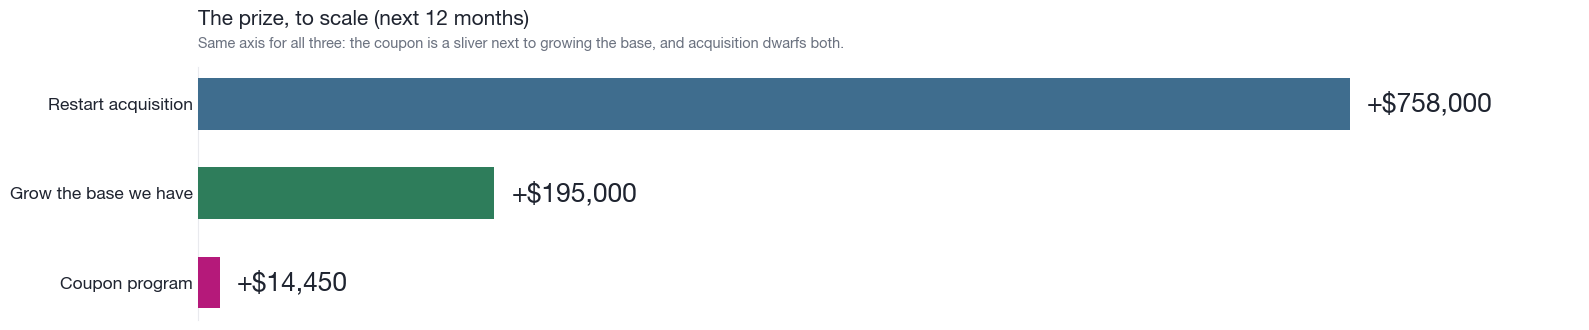

In [11]:
plt.rcParams["font.family"] = ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"]


def fig_roadmap_scale():
    m = seg.merge(
        chan.rename(columns={"channel_name": "acquisition_channel"}),
        on="acquisition_channel",
    )
    g = m.groupby("acquisition_channel").agg(
        n=("customer_id", "size"),
        fv=("future_value", "sum"),
        cps=("cost_per_signup", "first"),
        rsr=("revenue_share_rate", "first"),
    )
    acq = float((g.fv - g.fv * g.rsr - g.n * g.cps).sum())
    acq_lbl = round(acq / 1000.0) * 1000.0

    base = 195000.0
    coupon = float(alloc.net_revenue.sum())

    labels = ["Restart acquisition", "Grow the base we have", "Coupon program"]
    values = [acq, base, coupon]
    lblvals = [acq_lbl, base, coupon]
    colors = [BLUE, GREEN, MAGENTA]

    fig, ax = plt.subplots(figsize=(16, 3.4))
    y = np.arange(len(labels))
    ax.barh(y, values, height=0.58, color=colors, zorder=3)

    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=12.5, color=INK)
    ax.invert_yaxis()

    vmax = max(values)
    ax.set_xlim(0, vmax * 1.20)

    for yi, v, lv, c in zip(y, values, lblvals, colors):
        ax.text(
            v + vmax * 0.015, yi, f"+\${lv:,.0f}",
            va="center", ha="left", fontsize=19, fontweight="bold", color=INK,
        )

    ax.get_xaxis().set_visible(False)
    ax.grid(False)
    for s in ("top", "right", "bottom"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_visible(True)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["left"].set_color(GRID)
    ax.tick_params(axis="y", length=0)

    ax.set_title(
        "The prize, to scale (next 12 months)",
        loc="left", fontsize=15, fontweight="bold", color=INK, pad=30,
    )
    ax.text(
        0, 1.06,
        "Same axis for all three: the coupon is a sliver next to growing the base, and acquisition dwarfs both.",
        transform=ax.transAxes, fontsize=10.5, color=MUTED, va="bottom", ha="left",
    )

    plt.tight_layout()
    plt.show()


fig_roadmap_scale()


## Summary

Every figure in `Business-Presentation.pptx` is shown above with the numbers behind it recomputed from source. The
segment sizes/values, concentration (23x), category returns, CLV drivers, the three-question tree,
the coupon plan totals, the aisle matrix, VIP aisle dominance, the acquisition net (+\$757,767), and
the lapsed pool all reproduce exactly. The only figures that are **model/scenario assumptions**
(flagged inline) are the per-coupon lift and the +\$195k migration upside, which come from the lift
curves and migration scenario in `solutions.ipynb` and should be confirmed with a live A/B test.